In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [9]:

np.random.seed(42)

n = 300

area = np.random.randint(500, 4000, n)
bedrooms = np.random.randint(1, 6, n)
bathrooms = np.random.randint(1, 5, n)
floors = np.random.randint(1, 4, n)
age = np.random.randint(0, 31, n)

# Generate sample prices in Indian rupees
price = (
    area * 3000
    + bedrooms * 300000
    + bathrooms * 200000
    + floors * 100000
    - age * 20000
    + np.random.normal(0, 300000, n)
)

price = np.maximum(price, 500000)

df = pd.DataFrame({
    "Area": area,
    "Bedrooms": bedrooms,
    "Bathrooms": bathrooms,
    "Floors": floors,
    "Age": age,
    "Price": price.astype(int)
})

df.head()


,Area,Bedrooms,Bathrooms,Floors,Age,Price
0,3674,4,3,2,0,12555011
1,1360,1,4,2,19,5181802
2,1794,1,1,2,29,5117871
3,1630,2,1,2,6,6296438
4,1595,1,3,2,26,4740421


In [10]:
df.to_csv("house_prices.csv", index=False)

print("CSV file created successfully!")


CSV file created successfully!


In [11]:
from google.colab import files

files.download("house_prices.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

X = df[[
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "Age"
]]

y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 240
Testing rows: 60


In [13]:

model = LinearRegression()

model.fit(X_train, y_train)

print("House price prediction model trained successfully!")


House price prediction model trained successfully!


In [14]:

predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error: ₹", round(mae, 2))
print("R2 Score:", round(r2, 3))


Mean Absolute Error: ₹ 212488.5
R2 Score: 0.991


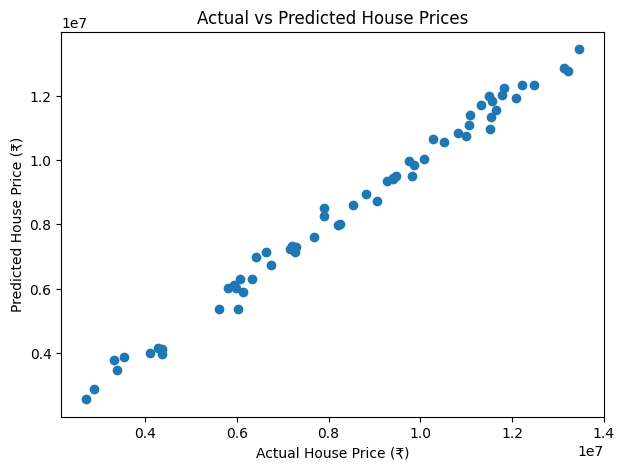

In [15]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)

plt.xlabel("Actual House Price (₹)")
plt.ylabel("Predicted House Price (₹)")
plt.title("Actual vs Predicted House Prices")

plt.show()


In [16]:

new_house = pd.DataFrame([{
    "Area": 1500,
    "Bedrooms": 3,
    "Bathrooms": 2,
    "Floors": 2,
    "Age": 5
}])

predicted_price = model.predict(new_house)[0]

print("Estimated House Price: ₹", round(predicted_price, 2))
print("Estimated Price in Lakhs: ₹",
      round(predicted_price / 100000, 2), "lakhs")


Estimated House Price: ₹ 5972102.26
Estimated Price in Lakhs: ₹ 59.72 lakhs
